<div style="display: flex; justify-content: flex-start; align-items: center;">
    <a href="https://colab.research.google.com/github/msfasha/307307-BI-Methods-Generative-AI/blob/main/20261/Module%202%20-%20LLMs%20and%20Reasoning/Module2_LLMs_and_Reasoning_lab.ipynb" target="_blank">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="height: 25px;">
    </a>
</div>

<div style="background:#F5EDF4; border-top:3px solid #A83296; padding:15px; border-radius:0 0 8px 8px">
<h1 style="color:#493347; margin:0">Lab — LLMs &amp; Reasoning: The Brain (Module 2)</h1>
<p style="color:#655263; margin:4px 0 0 0">Intro to Generative AI / Agentic AI — University of Petra</p>
</div>

**Course:** 307307 BI Methods for Generative AI (Agentic AI half)  
**Reference:** Grootendorst &amp; Alammar, *An Illustrated Guide to AI Agents* (O'Reilly, 2026), Chapter 2.

In Module 1 the `TinyAgent` had no brain — it just echoed you. Today we give it one. We build a small, reusable **`LLM` wrapper** that talks to Google **Gemini** through an OpenAI-compatible endpoint, add a **`Trajectory`** so we can see what the agent did, and wire it all into the agent.

**What you will do:**
1. Send messages in the **chat format** (system / user / assistant) and read the reply.
2. Build a reusable **`LLM`** class (the brain).
3. See what **temperature** changes.
4. Add a **`Trajectory`** and upgrade the `TinyAgent` to use the brain.

> The book builds this same class with raw `urllib`. We use the `openai` client pointed at Gemini — exactly the same endpoint, just fewer lines. Either way, there is no magic: it is one web request.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 0 — Setup</h2>
</div>

Reuse your free Gemini key from Module 1 (get one at https://aistudio.google.com/apikey). Keep it hidden; never paste it into a code cell.

In [ ]:
# In Google Colab, remove the leading # to install. Locally, run once.
# %pip install -q openai

In [ ]:
import os
from getpass import getpass
if not os.environ.get('GEMINI_API_KEY'):
    os.environ['GEMINI_API_KEY'] = getpass('Paste your Gemini API key (hidden): ')

# A model enabled on your account. Your Practical/Google_AI_Studio lab uses 'gemini-3.8-flash'.
MODEL = 'gemini-3.8-flash'

# Gemini's OpenAI-compatible endpoint. Swapping provider later = change these two lines.
BASE_URL = 'https://generativelanguage.googleapis.com/v1beta/openai/'
print('Key set:', bool(os.environ.get('GEMINI_API_KEY')), '| Model:', MODEL)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 1 — The chat message format</h2>
</div>

We talk to an LLM with a **list of messages**, each with a **role**:
- `system` — sets behavior before the user speaks (privileged).
- `user` — what the person asks.
- `assistant` — what the model replies.

Let's make one raw call and look at what comes back.

<div align="center">
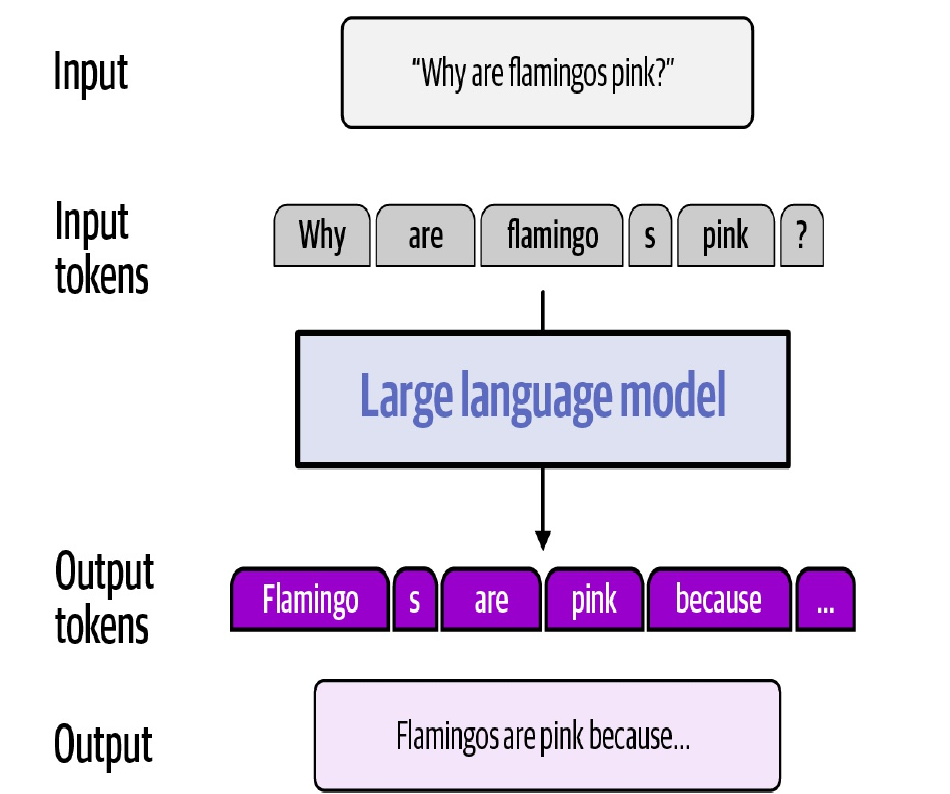
<br><span style="color:#6E6E6E; font-size:90%"><i>An LLM splits text into tokens and generates the answer one token at a time (Figure 2-3). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
from openai import OpenAI

client = OpenAI(api_key=os.environ['GEMINI_API_KEY'], base_url=BASE_URL)

messages = [
    {'role': 'system', 'content': 'You are a concise, friendly tutor.'},
    {'role': 'user', 'content': "Hi! In one sentence, what is a token in an LLM?"},
]

try:
    resp = client.chat.completions.create(model=MODEL, messages=messages)
    print('ASSISTANT:', resp.choices[0].message.content)
    print('TOKENS used:', resp.usage.prompt_tokens, 'in /', resp.usage.completion_tokens, 'out')
except Exception as e:
    print(f'[Call failed: {type(e).__name__}: {e}]')

Notice three things: the reply is just **text**, it came back under the **assistant** role, and the response carries **metadata** (how many tokens went in and out). Tokens are what you are billed on and what the context window counts.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 2 — Build the LLM wrapper (the brain)</h2>
</div>

Different providers return slightly different shapes. We wrap each reply into one tidy `Response` object (`content`, `reasoning`, `tool_call`, `metadata`) — the same design the book uses. We will fill in `reasoning` and `tool_call` in later modules; today we just need `content`.

In [ ]:
from dataclasses import dataclass

@dataclass
class Response:
    """A tidy, provider-independent LLM reply."""
    content: str = ''
    reasoning: str | None = None
    tool_call: dict | None = None
    metadata: dict | None = None


class LLM:
    """A minimal wrapper over any OpenAI-compatible endpoint (here: Gemini)."""

    def __init__(self, model: str, base_url: str = BASE_URL,
                 api_key: str | None = None, temperature: float | None = None):
        self.model = model
        self.temperature = temperature
        self.client = OpenAI(api_key=api_key or os.environ['GEMINI_API_KEY'],
                             base_url=base_url)

    def generate(self, messages: list[dict]) -> Response:
        kwargs = {'model': self.model, 'messages': messages}
        if self.temperature is not None:
            kwargs['temperature'] = self.temperature
        r = self.client.chat.completions.create(**kwargs)
        msg = r.choices[0].message
        return Response(
            content=msg.content,
            reasoning=getattr(msg, 'reasoning', None),
            metadata={'model': r.model,
                      'prompt_tokens': r.usage.prompt_tokens,
                      'completion_tokens': r.usage.completion_tokens},
        )

llm = LLM(model=MODEL)
print(llm.generate([{'role': 'user', 'content': 'Say hello in exactly four words.'}]))

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 3 — Temperature</h2>
</div>

Temperature controls how the model **picks** the next token. At **0** it always takes the most likely token (focused, repeatable). Higher values allow more variety. Run the next cell and compare the two lists.

<div align="center">
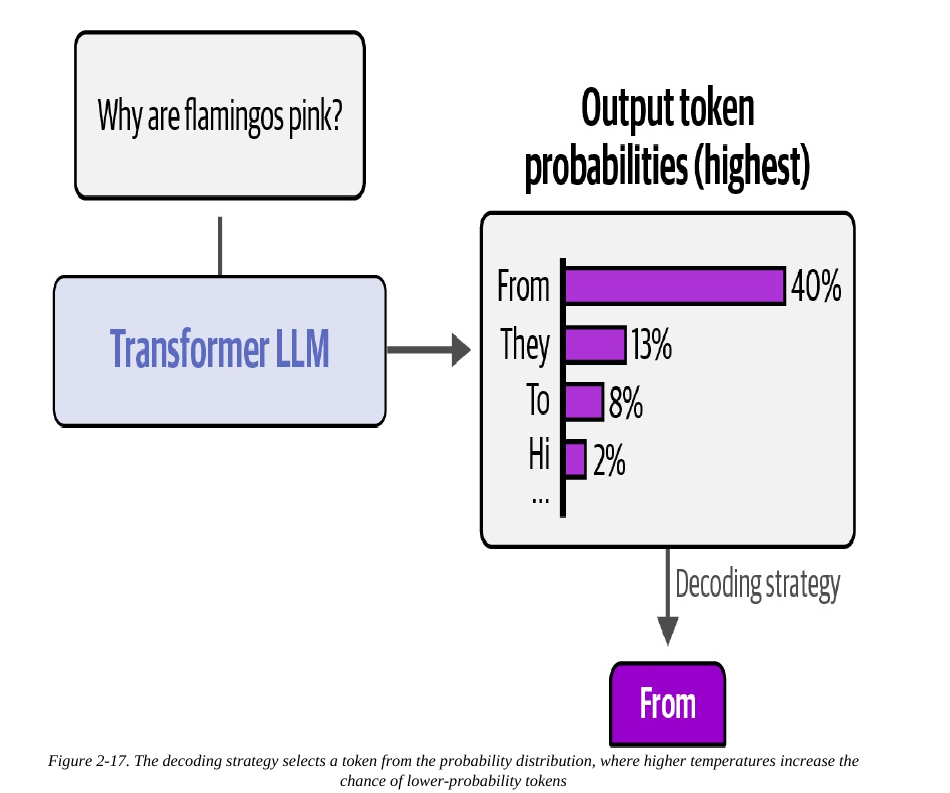
<br><span style="color:#6E6E6E; font-size:90%"><i>Decoding picks a token from the probabilities; temperature controls how (Figure 2-17). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

In [ ]:
prompt = [{'role': 'user', 'content': 'Give a creative two-word name for a coffee shop.'}]

cold = LLM(model=MODEL, temperature=0.0)
hot  = LLM(model=MODEL, temperature=1.2)

try:
    print('temperature 0.0 (focused):')
    for _ in range(3): print('  -', cold.generate(prompt).content)
    print('temperature 1.2 (varied):')
    for _ in range(3): print('  -', hot.generate(prompt).content)
except Exception as e:
    print(f'[Call failed: {type(e).__name__}: {e}]')

Low temperature tends to repeat the same safe answer; high temperature wanders. For agents that must behave reliably, we usually keep temperature low.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 4 — Trajectory + the upgraded TinyAgent</h2>
</div>

An agent may take many steps. To debug it, we record a **`Trajectory`** of **`Step`s**. (The `thought` / `action` / `observation` fields become important in the Tools and Planning modules; today a step just holds the final `answer`.)

In [ ]:
@dataclass
class Step:
    """One step in an agent run."""
    thought: str = ''
    action: dict | None = None
    observation: str | None = None
    answer: str | None = None
    metadata: dict | None = None

class Trajectory:
    """Records agent runs so we can inspect what happened."""
    def __init__(self):
        self.runs = []
    def initialize(self, query: str):
        self.runs.append({'query': query, 'steps': []})
    def add(self, response: Response, observation: str | None = None):
        step = Step(thought=response.reasoning or '', metadata=response.metadata)
        if observation is not None:
            step.action, step.observation = response.tool_call, observation
        else:
            step.answer = response.content
        self.runs[-1]['steps'].append(step)

In [ ]:
class TinyAgent:
    """The TinyAgent, now with a brain and a trajectory."""
    def __init__(self, llm: LLM, system_prompt: str = 'You are a helpful assistant.'):
        self.llm = llm
        self.system_prompt = system_prompt
        self.memory = None    # Module 3: Memory
        self.tools = None     # Module 4: Tools
        self.planner = None   # Module 5: Planning
        self.trajectory = Trajectory()

    def run(self, task: str) -> str:
        self.trajectory.initialize(task)
        return self._step(task)

    def _step(self, task: str) -> str:
        messages = [
            {'role': 'system', 'content': self.system_prompt},
            {'role': 'user', 'content': task},
        ]
        response = self.llm.generate(messages)
        self.trajectory.add(response)
        return response.content

agent = TinyAgent(llm=LLM(model=MODEL, temperature=0.0))
print(agent.run('What is 2 + 2? Answer in one short sentence.'))

Now inspect the trajectory — this is how we will debug multi-step agents later.

In [ ]:
for run in agent.trajectory.runs:
    print('QUERY:', run['query'])
    for i, step in enumerate(run['steps']):
        print(f'  step {i}: answer={step.answer!r}')
        print('           metadata=', step.metadata)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Exercise</h2>
</div>

**Task A.** Build a `TinyAgent` whose `system_prompt` makes it reply **only in bullet points**, then run it on *"List 3 uses of AI agents"*.

**Task B (think, no code).** In a comment, say which would be better for this task — **temperature 0** or **temperature 1.5** — and why.

Fill in the `# YOUR CODE HERE` lines, then check the solution below.

In [ ]:
# YOUR CODE HERE
# Task A: a bullet-point agent
# bullet_agent = TinyAgent(llm=LLM(model=MODEL, temperature=...), system_prompt=...)
# print(bullet_agent.run('List 3 uses of AI agents'))

# Task B (answer in a comment): temperature 0 or 1.5 for a factual list? Why?
# Answer: ...

**Solution** (try it yourself first):

In [ ]:
# --- Solution ---
# Task A
bullet_agent = TinyAgent(
    llm=LLM(model=MODEL, temperature=0.2),
    system_prompt='You reply ONLY as a short bulleted list, one idea per bullet.'
)
print(bullet_agent.run('List 3 uses of AI agents'))

# Task B
# Temperature 0 (low) is better here: a factual list should be focused and repeatable,
# not creative. High temperature would add randomness we do not want for facts.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Summary and what we built</h2>
</div>

Today you:
- Used the **chat format** (system / user / assistant) and read the reply + token metadata.
- Built a reusable **`LLM`** brain over Gemini's OpenAI-compatible endpoint.
- Saw what **temperature** changes.
- Added a **`Trajectory`** and upgraded the `TinyAgent` to use the brain.

```
TinyAgent/
  agent.py        <- updated: now uses the LLM
  llm.py          <- new: the brain (reusable wrapper)
  trajectory.py   <- new: records what the agent did
```

The agent still answers only a single turn and forgets everything afterwards — it is **stateless**. **Next module (Memory):** we give it a memory so it can hold a real conversation.

**Further reading:** *An Illustrated Guide to AI Agents*, Chapter 2 (LLMs) and Chapter 3 (Reasoning LLMs).